In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
mean, std = 0.2860, 0.3530

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])
train_tf_plain = test_tf

train_tf_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,)),
])

train_plain = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_plain)
train_aug   = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=train_tf_aug)
test_ds     = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=test_tf)

def loaders(train_ds, bs=128):
    return (DataLoader(train_ds, batch_size=bs, shuffle=True),
            DataLoader(test_ds, batch_size=256, shuffle=False))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.6MB/s]


In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10,
                 use_bn=False, p_drop=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [4]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum / total, correct / total

def run_training(model, train_dl, test_dl, epochs=10, lr=1e-3, verbose=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    n = len(train_dl.dataset)

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            run_loss += loss.item() * yb.numel()

        tr_loss = run_loss / n
        te_loss, acc = evaluate(model, test_dl)
        hist["train_loss"].append(tr_loss)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(acc)

        if verbose:
            print(f"Epoka {epoch:2d}/{epochs} | Trening strata: {tr_loss:.4f} | Test strata: {te_loss:.4f} | Accuracy: {acc*100:.2f}%")

    return hist

In [5]:
EPOCHS = 10
results = {}

tr_dl_plain, te_dl = loaders(train_plain)
tr_dl_aug, _ = loaders(train_aug)

In [6]:
print("== 1. Baseline (dane bez augmentacji, brak regularyzacji) ==")
model_base = MLP(use_bn=False, p_drop=0.0)
results["Baseline"] = run_training(model_base, tr_dl_plain, te_dl, epochs=EPOCHS, verbose=True)

== 1. Baseline (dane bez augmentacji, brak regularyzacji) ==
Epoka  1/10 | Trening strata: 0.4894 | Test strata: 0.4160 | Accuracy: 84.61%
Epoka  2/10 | Trening strata: 0.3508 | Test strata: 0.3548 | Accuracy: 87.16%
Epoka  3/10 | Trening strata: 0.3126 | Test strata: 0.3528 | Accuracy: 87.33%
Epoka  4/10 | Trening strata: 0.2846 | Test strata: 0.3458 | Accuracy: 87.70%
Epoka  5/10 | Trening strata: 0.2666 | Test strata: 0.3456 | Accuracy: 87.46%
Epoka  6/10 | Trening strata: 0.2522 | Test strata: 0.3286 | Accuracy: 88.17%
Epoka  7/10 | Trening strata: 0.2349 | Test strata: 0.3241 | Accuracy: 88.44%
Epoka  8/10 | Trening strata: 0.2234 | Test strata: 0.3348 | Accuracy: 88.52%
Epoka  9/10 | Trening strata: 0.2108 | Test strata: 0.3331 | Accuracy: 88.60%
Epoka 10/10 | Trening strata: 0.1982 | Test strata: 0.3662 | Accuracy: 88.08%


In [7]:
print("\n== 2. Tylko Augmentacja (dane z augmentacją, brak regularyzacji) ==")
model_aug = MLP(use_bn=False, p_drop=0.0)
results["Augmentacja"] = run_training(model_aug, tr_dl_aug, te_dl, epochs=EPOCHS, verbose=True)


== 2. Tylko Augmentacja (dane z augmentacją, brak regularyzacji) ==
Epoka  1/10 | Trening strata: 0.8199 | Test strata: 0.6302 | Accuracy: 75.46%
Epoka  2/10 | Trening strata: 0.6292 | Test strata: 0.5726 | Accuracy: 78.59%
Epoka  3/10 | Trening strata: 0.5754 | Test strata: 0.5365 | Accuracy: 79.76%
Epoka  4/10 | Trening strata: 0.5487 | Test strata: 0.5049 | Accuracy: 81.37%
Epoka  5/10 | Trening strata: 0.5281 | Test strata: 0.4948 | Accuracy: 81.67%
Epoka  6/10 | Trening strata: 0.5112 | Test strata: 0.5279 | Accuracy: 80.16%
Epoka  7/10 | Trening strata: 0.4991 | Test strata: 0.4715 | Accuracy: 82.61%
Epoka  8/10 | Trening strata: 0.4838 | Test strata: 0.4548 | Accuracy: 83.29%
Epoka  9/10 | Trening strata: 0.4767 | Test strata: 0.4571 | Accuracy: 82.47%
Epoka 10/10 | Trening strata: 0.4709 | Test strata: 0.4550 | Accuracy: 83.15%


In [8]:
print("\n== 3. Tylko BatchNorm (dane bez augmentacji, włączony BatchNorm) ==")
model_bn = MLP(use_bn=True, p_drop=0.0)
results["BatchNorm"] = run_training(model_bn, tr_dl_plain, te_dl, epochs=EPOCHS, verbose=True)


== 3. Tylko BatchNorm (dane bez augmentacji, włączony BatchNorm) ==
Epoka  1/10 | Trening strata: 0.4562 | Test strata: 0.4002 | Accuracy: 84.95%
Epoka  2/10 | Trening strata: 0.3278 | Test strata: 0.3695 | Accuracy: 86.36%
Epoka  3/10 | Trening strata: 0.2902 | Test strata: 0.3487 | Accuracy: 87.30%
Epoka  4/10 | Trening strata: 0.2657 | Test strata: 0.3320 | Accuracy: 87.79%
Epoka  5/10 | Trening strata: 0.2425 | Test strata: 0.3283 | Accuracy: 88.04%
Epoka  6/10 | Trening strata: 0.2277 | Test strata: 0.3058 | Accuracy: 89.02%
Epoka  7/10 | Trening strata: 0.2122 | Test strata: 0.3323 | Accuracy: 88.36%
Epoka  8/10 | Trening strata: 0.1969 | Test strata: 0.3215 | Accuracy: 88.82%
Epoka  9/10 | Trening strata: 0.1833 | Test strata: 0.3329 | Accuracy: 88.68%
Epoka 10/10 | Trening strata: 0.1727 | Test strata: 0.3140 | Accuracy: 89.16%


In [9]:
print("\n== 4. Tylko Dropout (dane bez augmentacji, włączony Dropout p=0.3) ==")
model_drop = MLP(use_bn=False, p_drop=0.3)
results["Dropout"] = run_training(model_drop, tr_dl_plain, te_dl, epochs=EPOCHS, verbose=True)


== 4. Tylko Dropout (dane bez augmentacji, włączony Dropout p=0.3) ==
Epoka  1/10 | Trening strata: 0.5553 | Test strata: 0.4096 | Accuracy: 85.03%
Epoka  2/10 | Trening strata: 0.4110 | Test strata: 0.3793 | Accuracy: 85.98%
Epoka  3/10 | Trening strata: 0.3727 | Test strata: 0.3686 | Accuracy: 86.60%
Epoka  4/10 | Trening strata: 0.3488 | Test strata: 0.3550 | Accuracy: 87.36%
Epoka  5/10 | Trening strata: 0.3351 | Test strata: 0.3476 | Accuracy: 87.60%
Epoka  6/10 | Trening strata: 0.3196 | Test strata: 0.3441 | Accuracy: 87.60%
Epoka  7/10 | Trening strata: 0.3125 | Test strata: 0.3364 | Accuracy: 87.75%
Epoka  8/10 | Trening strata: 0.3036 | Test strata: 0.3333 | Accuracy: 88.03%
Epoka  9/10 | Trening strata: 0.2914 | Test strata: 0.3294 | Accuracy: 88.20%
Epoka 10/10 | Trening strata: 0.2864 | Test strata: 0.3309 | Accuracy: 88.14%


In [10]:
print("\n== 5. Najlepsza konfiguracja (Augmentacja + BatchNorm + Dropout) ==")
model_best = MLP(use_bn=True, p_drop=0.3)
results["Najlepszy (Aug+BN+Drop)"] = run_training(model_best, tr_dl_aug, te_dl, epochs=EPOCHS, verbose=True)


== 5. Najlepsza konfiguracja (Augmentacja + BatchNorm + Dropout) ==
Epoka  1/10 | Trening strata: 0.9471 | Test strata: 0.6647 | Accuracy: 75.13%
Epoka  2/10 | Trening strata: 0.7519 | Test strata: 0.6111 | Accuracy: 77.78%
Epoka  3/10 | Trening strata: 0.7081 | Test strata: 0.5760 | Accuracy: 78.33%
Epoka  4/10 | Trening strata: 0.6786 | Test strata: 0.5494 | Accuracy: 79.72%
Epoka  5/10 | Trening strata: 0.6580 | Test strata: 0.5520 | Accuracy: 79.47%
Epoka  6/10 | Trening strata: 0.6414 | Test strata: 0.5170 | Accuracy: 80.95%
Epoka  7/10 | Trening strata: 0.6250 | Test strata: 0.5165 | Accuracy: 80.67%
Epoka  8/10 | Trening strata: 0.6160 | Test strata: 0.4938 | Accuracy: 81.78%
Epoka  9/10 | Trening strata: 0.6055 | Test strata: 0.4875 | Accuracy: 81.82%
Epoka 10/10 | Trening strata: 0.5972 | Test strata: 0.4867 | Accuracy: 82.20%


Konfiguracja              | Accuracy (test) | Przerwa train-test (strata)
---------------------------------------------------------------------------
Baseline                  |          88.08% |     0.1680
Augmentacja               |          83.15% |    -0.0159
BatchNorm                 |          89.16% |     0.1413
Dropout                   |          88.14% |     0.0446
Najlepszy (Aug+BN+Drop)   |          82.20% |    -0.1105
---------------------------------------------------------------------------


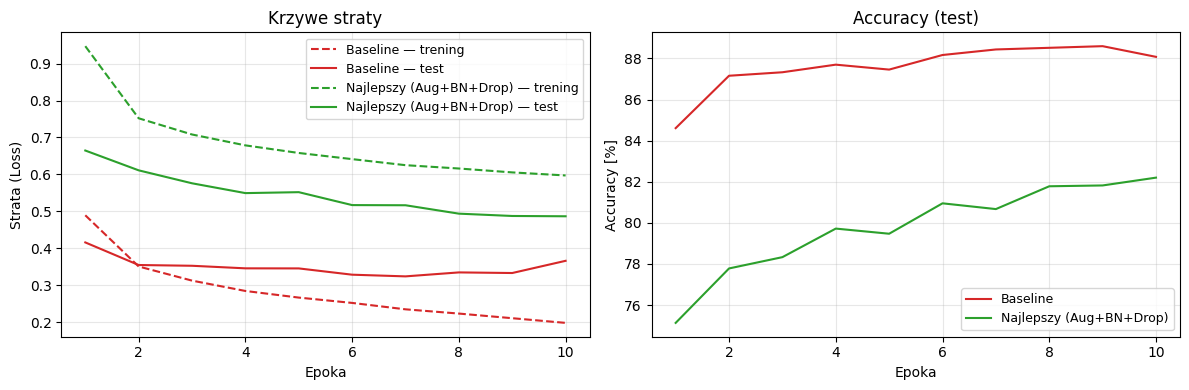

In [11]:
print(f"{'Konfiguracja':<25} | {'Accuracy (test)':<15} | {'Przerwa train-test (strata)'}")
print("-" * 75)

for name, hist in results.items():
    acc = hist["test_acc"][-1] * 100
    gap = hist["test_loss"][-1] - hist["train_loss"][-1]
    print(f"{name:<25} | {acc:>14.2f}% | {gap:>10.4f}")
print("-" * 75)

gap_base = results["Baseline"]["test_loss"][-1] - results["Baseline"]["train_loss"][-1]
gap_best = results["Najlepszy (Aug+BN+Drop)"]["test_loss"][-1] - results["Najlepszy (Aug+BN+Drop)"]["train_loss"][-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colors = {"Baseline": "tab:red", "Najlepszy (Aug+BN+Drop)": "tab:green"}

for name in ["Baseline", "Najlepszy (Aug+BN+Drop)"]:
    h = results[name]
    c = colors[name]
    ax1.plot(range(1, EPOCHS+1), h["train_loss"], "--", color=c, label=f"{name} — trening")
    ax1.plot(range(1, EPOCHS+1), h["test_loss"],  "-",  color=c, label=f"{name} — test")
    ax2.plot(range(1, EPOCHS+1), [a*100 for a in h["test_acc"]], color=c, label=name)

ax1.set_xlabel("Epoka")
ax1.set_ylabel("Strata (Loss)")
ax1.legend(fontsize=9)
ax1.set_title("Krzywe straty")
ax1.grid(True, alpha=0.3)

ax2.set_xlabel("Epoka")
ax2.set_ylabel("Accuracy [%]")
ax2.legend(fontsize=9)
ax2.set_title("Accuracy (test)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

== PRZEGLĄD WSPÓŁCZYNNIKA UCZENIA (LR) ==

Testowanie LR = 0.1
Epoka  1/4 | Trening strata: 4.1612 | Test strata: 2.3070 | Accuracy: 10.00%
Epoka  2/4 | Trening strata: 2.3095 | Test strata: 2.3115 | Accuracy: 10.00%
Epoka  3/4 | Trening strata: 2.3085 | Test strata: 2.3140 | Accuracy: 10.00%
Epoka  4/4 | Trening strata: 2.3081 | Test strata: 2.3135 | Accuracy: 9.99%

Testowanie LR = 0.01
Epoka  1/4 | Trening strata: 0.5146 | Test strata: 0.4416 | Accuracy: 84.73%
Epoka  2/4 | Trening strata: 0.4019 | Test strata: 0.4165 | Accuracy: 85.46%
Epoka  3/4 | Trening strata: 0.3793 | Test strata: 0.4340 | Accuracy: 85.42%
Epoka  4/4 | Trening strata: 0.3655 | Test strata: 0.4138 | Accuracy: 85.77%

Testowanie LR = 0.001
Epoka  1/4 | Trening strata: 0.4826 | Test strata: 0.4421 | Accuracy: 84.09%
Epoka  2/4 | Trening strata: 0.3514 | Test strata: 0.3873 | Accuracy: 86.26%
Epoka  3/4 | Trening strata: 0.3124 | Test strata: 0.3685 | Accuracy: 86.99%
Epoka  4/4 | Trening strata: 0.2889 | Test str

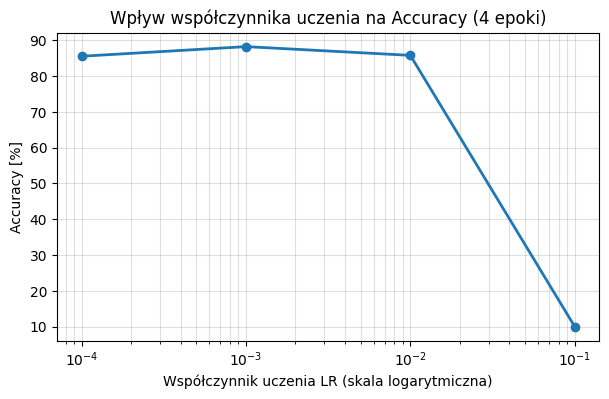

In [12]:
print("== PRZEGLĄD WSPÓŁCZYNNIKA UCZENIA (LR) ==")
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
acc_by_lr = []

for lr in lrs:
    print(f"\nTestowanie LR = {lr}")
    m = MLP(use_bn=False, p_drop=0.0)
    h = run_training(m, tr_dl_plain, te_dl, epochs=4, lr=lr, verbose=True)
    acc = h["test_acc"][-1]
    acc_by_lr.append(acc)

plt.figure(figsize=(7, 4))
plt.semilogx(lrs, [a*100 for a in acc_by_lr], marker="o", color="tab:blue", linewidth=2)
plt.xlabel("Współczynnik uczenia LR (skala logarytmiczna)")
plt.ylabel("Accuracy [%]")
plt.title("Wpływ współczynnika uczenia na Accuracy (4 epoki)")
plt.grid(True, which="both", alpha=0.4)
plt.show()